# Elektrik Talebi Tahmini — Veri Hazırlama

Büyük Britanya’nın yarım saatlik elektrik talebi kayıtlarını birleştiriyoruz. Hedefimiz ertesi günün her yarım saatlik dilimindeki talebi MW cinsinden tahmin etmek.

Kaynak: [NESO Historic Demand Data](https://www.neso.energy/data-portal/historic-demand-data), 2021–2025, NESO Open Data Licence.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

## Ham veri

In [2]:
raw_path = Path("data/raw")
source_columns = ["SETTLEMENT_DATE", "SETTLEMENT_PERIOD", "ND"]
column_names = dict(zip(source_columns, ["date", "settlement_period", "demand_mw"]))
date_formats = {
    2021: "%d-%b-%Y",
    2022: "%d-%b-%Y",
    2023: "%d-%b-%y",
    2024: "%d-%b-%Y",
    2025: "%Y-%m-%d",
}

yearly_data = []
for year, date_format in date_formats.items():
    year_df = pd.read_csv(raw_path / f"demanddata_{year}.csv", usecols=source_columns)
    year_df = year_df.rename(columns=column_names)
    year_df["date"] = pd.to_datetime(year_df["date"], format=date_format)
    yearly_data.append(year_df)

df = pd.concat(yearly_data, ignore_index=True)
df.head()

,date,settlement_period,demand_mw
0,2021-01-01,1,28354
1,2021-01-01,2,28501
2,2021-01-01,3,27759
3,2021-01-01,4,26912
4,2021-01-01,5,26004


## Veri hazırlama

Bir satır bir yarım saatlik ölçümü temsil ediyor. Birleşik dosyada eksik değerleri, tarih ve dilim tekrarlarını kontrol ediyoruz. Saat değişimindeki 46 ve 50 dilimli günler korunuyor.

In [3]:
print("Eksik değerler")
print(df.isna().sum())
print("\nTekrar eden tarih ve dilim:", df.duplicated(["date", "settlement_period"]).sum())

df = df.sort_values(["date", "settlement_period"]).reset_index(drop=True)
df.groupby(df["date"].dt.year)["demand_mw"].agg(["count", "min", "mean", "max"]).round(1)

Eksik değerler
date                 0
settlement_period    0
demand_mw            0
dtype: int64

Tekrar eden tarih ve dilim: 0


,count,min,mean,max
date,,,,
2021,17520,16309,28345.3,46433
2022,17520,14879,26622.3,46147
2023,17520,13601,26051.7,44109
2024,17568,15071,26286.8,45202
2025,17520,12803,26158.1,45924


## Keşifsel veri analizi

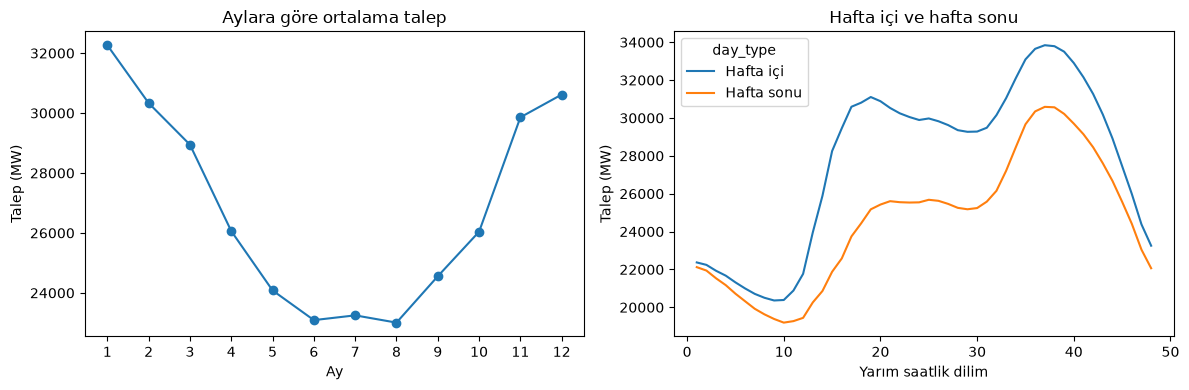

In [4]:
history = df[df["date"].dt.year < 2025]
monthly_mean = history.groupby(history["date"].dt.month)["demand_mw"].mean()
regular_days = history.groupby("date")["settlement_period"].transform("size").eq(48)
weekday_profile = (
    history.loc[regular_days]
    .assign(day_type=lambda data: data["date"].dt.dayofweek.ge(5).map({False: "Hafta içi", True: "Hafta sonu"}))
    .groupby(["settlement_period", "day_type"])["demand_mw"].mean()
    .unstack()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
monthly_mean.plot(ax=axes[0], marker="o", title="Aylara göre ortalama talep")
axes[0].set(xlabel="Ay", ylabel="Talep (MW)", xticks=range(1, 13))
weekday_profile.plot(ax=axes[1], title="Hafta içi ve hafta sonu")
axes[1].set(xlabel="Yarım saatlik dilim", ylabel="Talep (MW)")
plt.tight_layout()
plt.show()

Aylık ortalama ocakta 32.264 MW ile en yüksek, ağustosta 23.008 MW ile en düşük. Hafta içi talebi özellikle mesai başlangıcında hafta sonundan daha hızlı artıyor. Saat 18.00’de hafta içi ortalama 33.843 MW, hafta sonunda 30.587 MW.

## Aylara göre elektrik talebi

Kutu grafikleri 2021–2024 döneminde her ayın talep dağılımını gösteriyor.

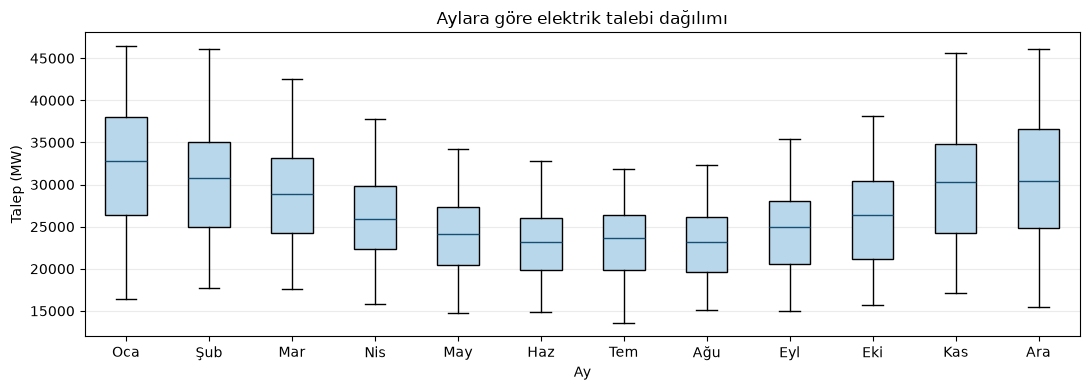

In [5]:
month_names = ["Oca", "Şub", "Mar", "Nis", "May", "Haz", "Tem", "Ağu", "Eyl", "Eki", "Kas", "Ara"]
monthly_demand = [
    history.loc[history["date"].dt.month.eq(month), "demand_mw"]
    for month in range(1, 13)
]

fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot(
    monthly_demand, tick_labels=month_names, patch_artist=True,
    boxprops={"facecolor": "#b8d7eb"}, medianprops={"color": "#174f73"},
    flierprops={"markersize": 2, "alpha": 0.25},
)
ax.set(title="Aylara göre elektrik talebi dağılımı", xlabel="Ay", ylabel="Talep (MW)")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

Ocak ayında talep medyanı 32.767 MW, ağustosta 23.235 MW oldu. Kutu grafiği, kış aylarında ölçümlerin genel olarak daha yüksek değerlere dağıldığını gösteriyor.

## Hazırlanan veriyi kaydetme

In [6]:
processed_path = Path("data/processed/electricity_demand.csv")
processed_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(processed_path, index=False)

print(f"{len(df):,} kayıt kaydedildi: {processed_path}")

87,648 kayıt kaydedildi: data\processed\electricity_demand.csv
